# Grape variety over vintages
Predict Chardonnay vs Sauvignon Blanc from review text in Napa Valley, 2004-2015.

Compare an original model with yearly retraining, then mask grape names to test how much explicit labels help.


## 1. Load data


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Requires pandas, numpy, matplotlib and scikit-learn.
local_paths = [Path("datasets/winemag-data-130k-v2.csv"),
               Path("../datasets/winemag-data-130k-v2.csv")]
source = next((p for p in local_paths if p.exists()),
              "https://raw.githubusercontent.com/dylanhernandez1/DATA4401_Project3/main/datasets/winemag-data-130k-v2.csv")
df = pd.read_csv(source, index_col=0)
print(f"Loaded {len(df):,} reviews")


Loaded 129,971 reviews


## 2. Clean and keep Napa, 2004-2015


In [2]:
# Adapted from Kevin's vintage extraction: ignore winery-name years and NV.
def get_vintage(title, winery):
    if pd.isna(title):
        return pd.NA
    text = str(title)
    if pd.notna(winery) and text.startswith(str(winery) + " "):
        text = text[len(str(winery)):].strip()
    if re.search(r"\bNV\b", text, flags=re.IGNORECASE):
        return pd.NA
    years = re.findall(r"\b(?:19|20)\d{2}\b", text)
    return int(years[0]) if len(years) == 1 else pd.NA

clean = df.drop_duplicates(subset=["title", "description"]).copy()
clean["vintage"] = pd.array(
    [get_vintage(t, w) for t, w in zip(clean["title"], clean["winery"])], dtype="Int64")
napa = clean.loc[clean["region_1"].eq("Napa Valley") &
                 clean["vintage"].between(2004, 2015)].copy()
napa = napa.dropna(subset=["description", "variety", "vintage"])
napa = napa.loc[napa["description"].str.strip().ne("")].copy()
# Keep the earliest occurrence of repeated text, including punctuation/case changes.
napa["review_key"] = napa["description"].str.lower().str.replace(r"\W+", " ", regex=True).str.strip()
napa = napa.sort_values("vintage", kind="stable").drop_duplicates("review_key")
year_counts = napa.groupby("vintage").size()
# The 75-review rule applies to the whole Napa vintage, before choosing varieties.
napa = napa.loc[napa["vintage"].isin(year_counts[year_counts >= 75].index)].copy()
napa["vintage"] = napa["vintage"].astype(int)
print(f"Clean Napa scope: {len(napa):,} reviews")
display(napa["variety"].value_counts().head(8).rename("reviews").to_frame())


Clean Napa scope: 3,846 reviews


,reviews
variety,
Cabernet Sauvignon,1563
Chardonnay,352
Merlot,313
Bordeaux-style Red Blend,288
Sauvignon Blanc,287
Red Blend,241
Zinfandel,139
Syrah,92


## 3. Two white varieties and chronological splits


In [3]:
varieties = ["Chardonnay", "Sauvignon Blanc"]
model_df = napa.loc[napa["variety"].isin(varieties)].copy()
counts = pd.crosstab(model_df["vintage"], model_df["variety"]).reindex(
    index=sorted(napa["vintage"].unique()), columns=varieties, fill_value=0)
counts.insert(0, "All Napa", napa.groupby("vintage").size())
display(counts)

train = model_df.loc[model_df["vintage"] <= 2007].copy()
validation = model_df.loc[model_df["vintage"] == 2008].copy()
base = model_df.loc[model_df["vintage"] <= 2008].copy()
future = model_df.loc[model_df["vintage"] >= 2009].copy()
print(f"Initial training (2004-2007): {len(train)} | Validation (2008): {len(validation)}")
print(f"Refit original model (2004-2008): {len(base)} | Future tests (2009-2015): {len(future)}")


variety,All Napa,Chardonnay,Sauvignon Blanc
vintage,,,
2004,97,2,0
2005,221,8,2
2006,239,19,13
2007,323,18,15
2008,342,25,19
2009,443,27,31
2010,419,45,28
2011,319,29,26
2012,543,44,34


Initial training (2004-2007): 77 | Validation (2008): 44
Refit original model (2004-2008): 121 | Future tests (2009-2015): 518


## 4. Simple model check: unigrams vs bigrams
Choose settings using 2008 only. Compare training and validation to check overfitting.


In [4]:
settings = {"Unigrams": (1, 1), "Unigrams + bigrams": (1, 2)}

def make_model(ngram_range):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=ngram_range, min_df=2, max_features=10000)),
        ("classifier", LogisticRegression(C=1.0, max_iter=1000, random_state=42))
    ])

def scores(actual, predicted):
    return {"accuracy": accuracy_score(actual, predicted),
            "macro_f1": f1_score(actual, predicted, labels=varieties, average="macro", zero_division=0)}

checks = []
for name, grams in settings.items():
    candidate = make_model(grams).fit(train["description"], train["variety"])
    row = {"setting": name}
    for split_name, split in [("train", train), ("validation", validation)]:
        row.update({f"{split_name}_{k}": v for k, v in
                    scores(split["variety"], candidate.predict(split["description"])).items()})
    checks.append(row)
model_checks = pd.DataFrame(checks)
best_setting = model_checks.sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False, kind="stable").iloc[0]["setting"]
best_grams = settings[best_setting]
display(model_checks.round(3))
print("Selected:", best_setting)


,setting,train_accuracy,train_macro_f1,validation_accuracy,validation_macro_f1
0,Unigrams,0.987,0.986,0.750,0.706
1,Unigrams + bigrams,0.987,0.986,0.636,0.515


Selected: Unigrams


## 5. Mask explicit grape names
Use the same model settings for both text versions. Other grape-related descriptions remain.


In [5]:
grape_pattern = re.compile(
    r"\b(?:chardonnays?|chards?|sauvignon(?:[\s-]+blanc)?|sauv\.?(?:[\s-]+blanc)?|fum[eé][\s-]+blanc|s\.?b\.?)\b",
    flags=re.IGNORECASE)

def mask_grapes(text):
    return re.sub(r"\s+", " ", grape_pattern.sub(" ", text)).strip()

model_df["masked_description"] = model_df["description"].map(mask_grapes)
model_df["grape_name_mentioned"] = model_df["description"].str.contains(grape_pattern)
print(f"Explicit grape names/aliases in {model_df['grape_name_mentioned'].mean():.1%} of selected reviews")
display(model_df.groupby("variety")["grape_name_mentioned"].mean().rename("fraction mentioning a grape").round(3).to_frame())


Explicit grape names/aliases in 38.3% of selected reviews


,fraction mentioning a grape
variety,
Chardonnay,0.420
Sauvignon Blanc,0.338


## 6. Test each new vintage
Original model: trained through 2008. Updated model: refit on all earlier vintages. Fit TF-IDF only on each training set; never train on the test vintage.


In [6]:
records, predictions = [], []
last_models = {}
for view, column in [("Full text", "description"), ("Grape names masked", "masked_description")]:
    original_data = model_df.loc[model_df["vintage"] <= 2008]
    original_model = make_model(best_grams).fit(original_data[column], original_data["variety"])
    for year in range(2009, 2016):
        test = model_df.loc[model_df["vintage"] == year]
        past = model_df.loc[model_df["vintage"] < year]
        updated_model = make_model(best_grams).fit(past[column], past["variety"])
        for name, fitted, training in [("Original", original_model, original_data),
                                       ("Updated", updated_model, past)]:
            predicted = fitted.predict(test[column])
            majority = training["variety"].mode().iloc[0]
            baseline = np.repeat(majority, len(test))
            records.append({"text": view, "test_vintage": year, "model": name,
                            "train_n": len(training), "train_through": training["vintage"].max(),
                            "test_n": len(test), **scores(test["variety"], predicted),
                            "baseline_accuracy": accuracy_score(test["variety"], baseline)})
            predictions.append(pd.DataFrame({"text": view, "test_vintage": year, "model": name,
                                              "actual": test["variety"].to_numpy(), "predicted": predicted,
                                              "baseline": baseline}))
        last_models[view] = updated_model
vintage_results = pd.DataFrame(records)
all_predictions = pd.concat(predictions, ignore_index=True)
full_results = vintage_results.loc[vintage_results["text"].eq("Full text")]
display(full_results[["test_vintage", "model", "train_n", "test_n", "accuracy", "macro_f1", "baseline_accuracy"]].round(3).reset_index(drop=True))


,test_vintage,model,train_n,test_n,accuracy,macro_f1,baseline_accuracy
0,2009,Original,121,58,0.862,0.862,0.466
1,2009,Updated,121,58,0.862,0.862,0.466
2,2010,Original,121,73,0.945,0.940,0.616
3,2010,Updated,179,73,0.945,0.940,0.616
4,2011,Original,121,55,0.745,0.725,0.527
5,2011,Updated,252,55,0.836,0.831,0.527
6,2012,Original,121,78,0.833,0.820,0.564
7,2012,Updated,307,78,0.923,0.922,0.564
8,2013,Original,121,99,0.646,0.569,0.566
9,2013,Updated,385,99,0.747,0.709,0.566


## 7. Does updating help?


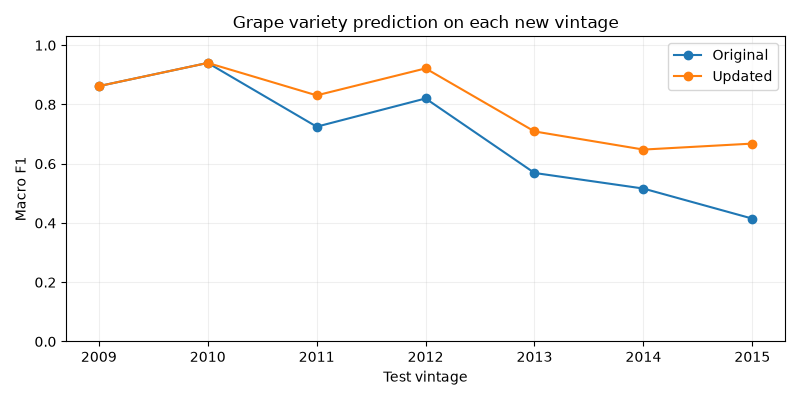

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, group in full_results.groupby("model", sort=False):
    ax.plot(group["test_vintage"], group["macro_f1"], marker="o", label=name)
ax.set(title="Grape variety prediction on each new vintage", xlabel="Test vintage", ylabel="Macro F1", ylim=(0, 1.03))
ax.set_xticks(range(2009, 2016))
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()


## 8. How much do explicit grape names help?


In [8]:
display(vintage_results.pivot(index="test_vintage", columns=["text", "model"], values="macro_f1").round(3))

# Pooled scores across all held-out 2009-2015 reviews (not average yearly F1).
summary_rows = []
for (view, name), group in all_predictions.groupby(["text", "model"], sort=False):
    summary_rows.append({"text": view, "model": name, "test_n": len(group),
                         **scores(group["actual"], group["predicted"]),
                         "baseline_accuracy": accuracy_score(group["actual"], group["baseline"])})
overall_results = pd.DataFrame(summary_rows)
display(overall_results.round(3))


text         Full text         Grape names masked        
model         Original Updated           Original Updated
test_vintage                                             
2009             0.862   0.862              0.719   0.719
2010             0.940   0.940              0.791   0.895
2011             0.725   0.831              0.628   0.811
2012             0.820   0.922              0.694   0.856
2013             0.569   0.709              0.593   0.650
2014             0.516   0.648              0.593   0.648
2015             0.415   0.668              0.481   0.668

,text,model,test_n,accuracy,macro_f1,baseline_accuracy
0,Full text,Original,518,0.728,0.697,0.541
1,Full text,Updated,518,0.807,0.795,0.541
2,Grape names masked,Original,518,0.685,0.645,0.541
3,Grape names masked,Updated,518,0.763,0.746,0.541


## 9. Important phrases
Positive class-specific weights from the last updated models, trained through 2014. These show associations, not causes.


In [9]:
for view, fitted in last_models.items():
    terms = fitted.named_steps["tfidf"].get_feature_names_out()
    classifier = fitted.named_steps["classifier"]
    # Binary logistic regression stores one coefficient row, for classes_[1].
    class_weights = [-classifier.coef_[0], classifier.coef_[0]]
    top_terms = {}
    for label, weights in zip(classifier.classes_, class_weights):
        top = np.argsort(weights)[-8:][::-1]
        top_terms[label] = [f"{terms[i]} ({weights[i]:.2f})" for i in top]
    print(view)
    display(pd.DataFrame(top_terms, index=range(1, 9)))


Full text


,Chardonnay,Sauvignon Blanc
1,chardonnay (3.31),sauvignon (2.86)
2,buttered (1.78),blanc (2.60)
3,toast (1.59),grapefruit (1.49)
4,apple (1.46),white (1.48)
5,oak (1.34),green (1.46)
6,oaky (1.27),gooseberry (1.45)
7,pineapple (1.26),sémillon (1.37)
8,caramel (1.20),touch (1.23)


Grape names masked


,Chardonnay,Sauvignon Blanc
1,buttered (1.96),green (1.64)
2,toast (1.74),gooseberry (1.61)
3,oaky (1.46),white (1.56)
4,apple (1.37),grapefruit (1.54)
5,oak (1.36),sémillon (1.51)
6,pineapple (1.29),citrus (1.44)
7,pear (1.27),touch (1.39)
8,caramel (1.25),lemongrass (1.22)


## 10. Later-vintage errors and composition
2015 predictions use the updated full-text model trained through 2014. Composition compares the original training era (2004-2008) with the final three vintages (2013-2015).


In [10]:
test_2015 = model_df.loc[model_df["vintage"].eq(2015)].copy()
test_2015["predicted"] = last_models["Full text"].predict(test_2015["description"])
confusion_2015 = pd.crosstab(test_2015["variety"], test_2015["predicted"]).reindex(
    index=varieties, columns=varieties, fill_value=0)
confusion_2015.columns = ["Predicted " + name for name in varieties]
confusion_2015["Recall"] = np.diag(confusion_2015.to_numpy()) / confusion_2015.sum(axis=1)
print("2015 confusion table: rows = actual variety")
display(confusion_2015.round(3))

period_df = model_df.loc[model_df["vintage"].le(2008) | model_df["vintage"].ge(2013)].copy()
period_df["period"] = np.where(period_df["vintage"].le(2008), "Early: 2004-2008", "Late: 2013-2015")
period_balance = period_df.groupby(["period", "variety"]).size().rename("reviews").to_frame()
period_balance["share_of_period"] = period_balance["reviews"] / period_balance.groupby(level=0)["reviews"].transform("sum")
print("Class balance")
display(period_balance.round(3))
reviewer_mix = pd.crosstab([period_df["period"], period_df["variety"]],
                           period_df["taster_name"].fillna("Unknown"), normalize="index")
print("Reviewer shares within each variety (missing credits = Unknown)")
display(reviewer_mix.round(3))

errors_2015 = test_2015.loc[test_2015["variety"].ne(test_2015["predicted"])].copy()
error_examples = errors_2015.groupby("variety", sort=False).head(2)
print(f"{len(errors_2015)} errors in {len(test_2015)} reviews; up to two examples per actual variety")
with pd.option_context("display.max_colwidth", 300):
    display(error_examples[["variety", "predicted", "description"]].reset_index(drop=True))


2015 confusion table: rows = actual variety


,Predicted Chardonnay,Predicted Sauvignon Blanc,Recall
variety,,,
Chardonnay,24,0,1.000
Sauvignon Blanc,18,14,0.438


Class balance


reviews  share_of_period
period           variety                                  
Early: 2004-2008 Chardonnay            72            0.595
                 Sauvignon Blanc       49            0.405
Late: 2013-2015  Chardonnay           135            0.531
                 Sauvignon Blanc      119            0.469

Reviewer shares within each variety (missing credits = Unknown)


taster_name                       Jim Gordon  Unknown  Virginie Boone
period           variety                                             
Early: 2004-2008 Chardonnay            0.000    1.000            0.00
                 Sauvignon Blanc       0.000    1.000            0.00
Late: 2013-2015  Chardonnay            0.000    0.000            1.00
                 Sauvignon Blanc       0.025    0.025            0.95

18 errors in 56 reviews; up to two examples per actual variety


,variety,predicted,description
0,Sauvignon Blanc,Chardonnay,"A beautifully rich and rewarding expression of tropical fruit and creamy texture, this estate white spends nine months in large French oak casks and is selected from the best lots. Supporting acidity keeps it refreshing in waves of lime and grapefruit."
1,Sauvignon Blanc,Chardonnay,"Fuzzy peach with a companionable co-host of Meyer lemon star in this medium-bodied, voluptuously appealing wine. It's balanced and easy to enjoy, its finish taking on added volume and likability."


## 11. Words changing within each variety
Compare the percentage of early vs late reviews containing each word, with grape names masked. Minimum five reviews per word across both periods; show four largest increases and decreases. Descriptive only, not used to tune the model.


In [11]:
from sklearn.feature_extraction.text import CountVectorizer

word_change_tables = {}
for variety in varieties:
    subset = period_df.loc[period_df["variety"].eq(variety)]
    words = CountVectorizer(binary=True, stop_words="english", min_df=5)
    counts = words.fit_transform(subset["masked_description"])
    early = subset["period"].str.startswith("Early").to_numpy()
    changes = pd.DataFrame({
        "word": words.get_feature_names_out(),
        "early_pct": np.asarray(counts[early].mean(axis=0)).ravel() * 100,
        "late_pct": np.asarray(counts[~early].mean(axis=0)).ravel() * 100
    })
    changes["change_pp"] = changes["late_pct"] - changes["early_pct"]
    word_change_tables[variety] = changes
    examples = pd.concat([changes.nsmallest(4, "change_pp"), changes.nlargest(4, "change_pp")])
    print(f"{variety}: {early.sum()} early reviews vs {(~early).sum()} late reviews")
    display(examples.round(1).reset_index(drop=True))


Chardonnay: 72 early reviews vs 135 late reviews


,word,early_pct,late_pct,change_pp
0,flavors,84.7,15.6,-69.2
1,pineapple,47.2,12.6,-34.6
2,sweet,29.2,3.0,-26.2
3,buttered,26.4,0.7,-25.6
4,wine,29.2,81.5,52.3
5,apple,5.6,48.1,42.6
6,bodied,0.0,34.8,34.8
7,lemon,6.9,31.9,24.9


Sauvignon Blanc: 49 early reviews vs 119 late reviews


,word,early_pct,late_pct,change_pp
0,flavors,77.6,19.3,-58.2
1,crisp,65.3,15.1,-50.2
2,dry,53.1,8.4,-44.7
3,limes,26.5,0.8,-25.7
4,bodied,0.0,27.7,27.7
5,peach,4.1,25.2,21.1
6,white,18.4,38.7,20.3
7,lemon,12.2,30.3,18.0


## Findings
- Unigrams performed better on 2008 validation than adding bigrams (75.0% vs 63.6% accuracy).
- Across 518 future reviews, yearly updating improved accuracy from 72.8% to 80.7% (majority baseline: 54.1%). In 2015 alone, accuracy was 48.2% vs 67.9%.
- Masked-text updating reached 76.3% accuracy: explicit grape names help, but other words remain predictive. Later-vintage performance still weakens.
- The 2015 updated model correctly identified all 24 Chardonnay reviews but only 14 of 32 Sauvignon Blanc reviews; all 18 errors were Sauvignon Blanc predicted as Chardonnay.
- Within Sauvignon Blanc, "crisp" fell from 65.3% to 15.1% of reviews and "dry" from 53.1% to 8.4% between the early and late periods. These are descriptive language changes, not proof of what caused the accuracy decline.


## Limits and next step
- This is a two-variety Napa task; results do not cover every grape variety.
- Vintage orders the batches; it is not the review publication year. Annual test samples are small.
- Masking tests explicit grape clues. Producer, reviewer and other wine cues can remain. Early reviewer credits are all missing, while late reviews are mostly credited to Virginie Boone, so writer comparability cannot be verified.
- Updating adds more data as well as more recent data; this experiment cannot separate those effects or prove the cause of later-vintage declines.

Vintage extraction adapted from `Price_Kevin.ipynb`. Notebook/code prepared with GenAI assistance; acknowledge this in the team submission.
